# 7Learnings Data Scientist Case Study: Retail Demand Forecasting

Forecast observed unit sales before returns for market `DE`, channel `myshop.de`, using the `(product_id, date)` pairs in `sample_prediction.csv` for **September 7–20, 2026**. The training cutoff is **September 6, 2026, 23:59:59**. See the README for the full task and dataset details.


## Deliverables

- Submit this notebook or a reproducible Python script/repository.
- Generate `predictions.csv` in the project directory with columns `product_id,date,predicted_sales`, covering the exact pairs in `sample_prediction.csv`.
- Include a baseline comparison, your investigation SQL and results, a compact supporting table or chart, and the client memo. Add code cells wherever you need them.


## Environment Setup & Data Preparation

Follow the README to install the dependencies and acquire the DuckDB database. Use the supplied tables and keep realized observations within the historical cutoff. The README defines which planned promotions are available for this forecast and how to handle them during historical validation.


In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DB = "7ldata.duckdb"
CUTOFF = "2026-09-06 23:59:59"
H_START, H_END = "2026-09-07", "2026-09-20"

con = duckdb.connect()
con.sql(f"ATTACH '{DB}' AS src (READ_ONLY)")


def q(sql):
    return con.sql(sql).df()

## AI Usage & Transparency

AI tools are permitted. Disclose which tools you used and how they helped. Be prepared to explain your analysis and assumptions.

### Candidate AI Disclosure
- AI assistants used: Claude (Claude Code, in VS Code).
- Tasks they assisted with: environment setup and data download, first drafts of the DuckDB SQL and pandas code, notebook structure, debugging. I decided the cleaning rules, validation design and recommendation, and checked them against the query outputs in this notebook.
- Prompts or queries used: task-level requests, one part at a time, with each part reviewed before the next. What I investigated and decided:
  - Data: checked table quality, whether duplicate lines double count sales, and whether each product has a complete daily series before modelling.
  - Features: went through how the 28-day variation, online-day count and weekday pattern are computed. Decided to keep the voucher out of the model, because it is 0 in every training row, and apply it afterwards as a separate +2% adjustment.
  - Models: compared LightGBM, XGBoost, scikit-learn gradient boosting and NHITS against the baseline. Dropped Prophet, because a full-catalog fit takes about 50 minutes per window, which doesn't fit the 3-hour limit.
  - Validation: pick the model on Aug 10–23 and report it on Aug 24 – Sep 6, so the reported result isn't inflated by choosing on the same days. Kept LightGBM even where another model did slightly better on the test window.
  - Metrics: WAPE as the main metric, with bias, MAE and RMSE alongside. No MAPE, because it breaks on small and zero sales. Defined how zero totals are handled.
  - Planner question: verified the drop first, then tested traffic, seasonality, promotion, stock and price, plus one sensitivity check, before making a recommendation.
  - Checks: every number in the write-up and memo appears in an output cell. The notebook runs top to bottom, and a second run gives an identical predictions.csv.
- Confirmation: I reviewed my submission and can explain its findings, assumptions, and decisions.

## Part 1: Data Analysis

Analyze the data’s structure, coverage, and relationships relevant to the forecast. Document any data preparation, transformations, or enrichment you choose and explain why.

### 1.1 What is in the file

In [2]:
q("""
select 'transactions' tbl, count(*) n_rows, count(distinct product_id) n_ids,
       min(time)::varchar first_ts, max(time)::varchar last_ts from src.transactions
union all select 'traffic', count(*), count(distinct product_id), min(active_since)::varchar, max(active_till)::varchar from src.traffic
union all select 'stock', count(*), count(distinct product_id), min(active_since)::varchar, max(active_since)::varchar from src.stock
union all select 'promotions', count(*), count(distinct product_id), min(active_since)::varchar, max(active_till)::varchar from src.promotions
union all select 'product_attributes', count(*), count(distinct product_id), null, null from src.product_attributes
""")

,tbl,n_rows,n_ids,first_ts,last_ts
0,transactions,2764520,13385,1970-01-01 00:00:00,2099-12-31 23:59:59
1,traffic,2736950,3920,2024-09-16 00:00:00,2026-09-20 23:59:59.999999
2,stock,27300,3900,2023-12-26,2026-09-11
3,promotions,8340,3920,2026-09-01 00:00:00,2026-10-05 23:59:59.999999
4,product_attributes,3920,3920,NaN,NaN


In [3]:
# only one market/channel in every table, so the DE / myshop.de filter below changes nothing but I keep it
q("""
select 'transactions' tbl, market, channel, count(*) n from src.transactions group by all
union all select 'traffic', market, channel, count(*) from src.traffic group by all
union all select 'stock', market, channel, count(*) from src.stock group by all
union all select 'promotions', market, channel, count(*) from src.promotions group by all
""")

,tbl,market,channel,n
0,transactions,DE,myshop.de,2764520
1,traffic,DE,myshop.de,2736950
2,stock,DE,myshop.de,27300
3,promotions,DE,myshop.de,8340


### 1.2 Transaction quality

Transactions has 13k distinct ids against 3,920 catalog products, and timestamps from 1970 to 2099, so I checked what is wrong before aggregating anything.

In [4]:
q(f"""
select
    count(*) total_rows,
    count(*) filter (where product_id is null) null_id,
    count(*) filter (where product_id <> trim(product_id)) padded_id,
    count(*) filter (where contains(product_id, '_X_')) upper_x_id,
    count(*) filter (where product_id in ('TEST_SKU_001', 'INTERNAL_TEST')) test_sku,
    count(*) filter (where time < '2024-01-01' or time >= '2027-01-01') bad_ts,
    count(*) filter (where sales_before_returns <= 0) qty_le_0,
    count(*) filter (where sales_before_returns >= 1000) qty_placeholder,
    count(*) filter (where returns > sales_before_returns and sales_before_returns > 0) returns_gt_qty,
    count(*) filter (where purchase_cost = 0 and revenue <= 0) zero_value_lines,
    count(*) filter (where time > '{CUTOFF}' and time < '2027-01-01') after_cutoff
from src.transactions
""").T.rename(columns={0: "rows"})

,rows
total_rows,2764520
null_id,13685
padded_id,20000
upper_x_id,5000
test_sku,200
bad_ts,50
qty_le_0,500
qty_placeholder,100
returns_gt_qty,500
zero_value_lines,12208


In [5]:
q("""
select sales_before_returns qty, count(*) n
from src.transactions
where sales_before_returns <= 0 or sales_before_returns > 30
group by 1 order by 1
""").T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
qty,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,31,32,33,34,35,36,37,38,39,41,42,43,10000,99999
n,41,40,43,51,50,63,60,63,37,52,14,17,15,10,12,4,4,4,6,3,1,1,50,50


### 1.3 Duplicates

Three questions, because a duplicate could hide in more than one way:

1. Are there rows that are identical in every column?
2. Are the broken ids (null, padded, upper-case) copies of a clean line? If yes they must be dropped, otherwise fixing the id would double count. If no, they are real sales.
3. Does the same order line (`order_id`, `basket_position`) appear with a different product, quantity, time or revenue? That would be a near-duplicate that question 1 misses.

In [6]:
# 1) full-row duplicates
cols = ", ".join(con.sql("select * from src.transactions limit 0").columns)
q(f"""
select n_copies, count(*) n_groups, count(*) * n_copies n_rows,
       min(first_ts)::date first_day, max(first_ts)::date last_day
from (select count(*) n_copies, min(time) first_ts from src.transactions group by {cols})
group by 1 order by 1
""")

,n_copies,n_groups,n_rows,first_day,last_day
0,1,2709780,2709780,1970-01-01,2099-12-31
1,2,27370,54740,2024-09-16,2026-09-20


In [7]:
# full-row duplicates per month - a load problem would be spread evenly, a real event would cluster
q(f"""
select date_trunc('month', first_ts)::date as month, count(*) duplicated_lines
from (select min(time) first_ts from src.transactions group by {cols} having count(*) > 1)
where year(first_ts) between 2024 and 2026
group by 1 order by 1
""").set_index("month").T

month,2024-09-01,2024-10-01,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01
duplicated_lines,621,1216,1143,1218,1225,1076,1198,1107,1299,1246,1228,1203,1145,1258,1134,902,1002,838,933,961,1051,1129,1230,1202,805


In [8]:
# 2) do the broken ids have a clean twin on the same order line?
q("""
select kind, count(*) n_rows,
       count(*) filter (where exists (
           select 1 from src.transactions c
           where c.order_id = r.order_id and c.basket_position = r.basket_position
             and c.product_id = lower(trim(c.product_id)))) n_with_clean_twin,
       count(*) filter (where exists (
           select 1 from src.transactions c
           where c.order_id = r.order_id and c.product_id is not null and c.basket_position <> r.basket_position)) n_order_has_other_lines
from (select *, case when product_id is null then 'null id'
                     when product_id <> trim(product_id) then 'padded id'
                     when contains(product_id, '_X_') then 'upper-case id' end kind
      from src.transactions) r
where kind is not null
group by 1
""")

,kind,n_rows,n_with_clean_twin,n_order_has_other_lines
0,upper-case id,5000,0,5000
1,padded id,20000,0,19991
2,null id,13685,0,13675


In [9]:
# 3) one order line, different content?
q("""
select count(*) order_lines,
       count(*) filter (where n_products > 1) with_different_products,
       count(*) filter (where n_versions > 1) with_different_qty_time_or_revenue
from (select order_id, basket_position,
             count(distinct lower(trim(product_id))) n_products,
             count(distinct (time, sales_before_returns, revenue)) n_versions
      from src.transactions group by all)
""")

,order_lines,with_different_products,with_different_qty_time_or_revenue
0,2737150,0,0


- 27,370 lines exist exactly twice, identical in every column, spread evenly over all months. That looks like a load issue, so I keep one copy.
- None of the padded or upper-case ids has a clean twin. They are real sales with a formatting problem, so I fix the id and keep them. Dropping them would lose 25k lines.
- Null-id lines also have no twin, and almost all sit in orders with other valid lines. They are real sales where the product id got lost. I come back to them in 1.5.
- No order line appears with two different contents, so there are no near-duplicates.

So after `distinct` and the id fix there is no double counting left.

### 1.4 Clean lines and the bad quantities

In [10]:
con.sql(f"""
create or replace table tx as
select lower(trim(product_id)) as product_id, time, time::date as d, order_id, basket_position,
       sales_before_returns as qty, returns, revenue, purchase_cost,
       case when sales_before_returns <= 0 then 'qty <= 0'
            when sales_before_returns >= 1000 then 'qty placeholder'
            when returns > sales_before_returns then 'returns > qty'
            when purchase_cost = 0 and revenue <= 0 then 'zero-value line'
            else 'ok' end as qty_flag
from (select distinct * from src.transactions)
where market = 'DE' and channel = 'myshop.de'
  and product_id is not null
  and time >= '2024-01-01' and time <= '{CUTOFF}'
""")
con.sql("delete from tx where product_id not in (select product_id from src.product_attributes)")

con.sql(f"""
create or replace table traffic_d as
select product_id, active_since::date as d, total_clicks as clicks, paid_clicks, marketing_cost
from src.traffic
where market = 'DE' and channel = 'myshop.de' and active_since <= '{CUTOFF}'
""")

q("""
select count(*) n_lines, count(distinct product_id) n_products, min(d) first_day, max(d) last_day,
       (select max(n) from (select count(*) n from tx group by product_id, d)) max_lines_per_product_day
from tx
""")

,n_lines,n_products,first_day,last_day,max_lines_per_product_day
0,2668586,3920,2024-09-16,2026-09-06,1


The negative quantities don't behave like returns: `returns` is 0 on all of them, revenue and purchase cost are positive and normal-sized, and there is no matching positive line for the same product that they could be reversing. My first guess was a sign flip, so I compared the recorded quantity with two independent estimates:

- cost-implied: `purchase_cost / product's median cost per unit`
- click-implied: `clicks that day * product's units-per-click`, both estimated on the clean lines only.

In [11]:
con.sql("""
create or replace table conv as
select x.product_id,
       sum(x.qty) / sum(t.clicks) as cr,
       median(x.purchase_cost / x.qty) filter (where x.purchase_cost > 0) as cost_per_unit
from tx x join traffic_d t using (product_id, d)
where x.qty_flag = 'ok'
group by 1
""")

q("""
select x.qty_flag, count(*) n_lines,
       median(x.qty) recorded_qty,
       round(median(x.purchase_cost / c.cost_per_unit), 1) qty_implied_by_cost,
       round(median(t.clicks * c.cr), 1) qty_implied_by_clicks,
       round(avg((round(t.clicks * c.cr) = x.qty)::int), 3) share_recorded_eq_click_implied,
       round(median(x.revenue)) median_revenue,
       count(*) filter (where x.returns > 0) lines_with_returns
from tx x join traffic_d t using (product_id, d) join conv c using (product_id)
group by 1 order by 2 desc
""")

,qty_flag,n_lines,recorded_qty,qty_implied_by_cost,qty_implied_by_clicks,share_recorded_eq_click_implied,median_revenue,lines_with_returns
0,ok,2655703,3.0,3.0,3.0,1.000,272.0,1416509
1,zero-value line,11812,1.0,0.0,1.0,1.000,-0.0,11812
2,returns > qty,491,1.0,3.0,3.0,0.002,259.0,491
3,qty <= 0,482,-5.0,3.0,3.0,0.000,275.0,0
4,qty placeholder,98,10000.0,3.8,4.0,0.000,273.0,52


In [12]:
# negative lines: is abs(qty) the real quantity? (sign flip test)
q("""
select x.qty, round(x.purchase_cost / c.cost_per_unit, 1) qty_implied_by_cost, round(t.clicks * c.cr) qty_implied_by_clicks
from tx x join traffic_d t using (product_id, d) join conv c using (product_id)
where x.qty_flag in ('qty <= 0', 'qty placeholder', 'returns > qty')
order by x.qty_flag, x.time
limit 12
""")

,qty,qty_implied_by_cost,qty_implied_by_clicks
0,-6,5.3,5.0
1,-2,2.0,2.0
2,-4,4.0,4.0
3,-4,5.3,5.0
4,-1,3.0,3.0
5,-4,3.7,4.0
6,-8,4.0,3.0
7,-3,2.5,3.0
8,-10,2.0,2.0
9,-8,4.0,4.0


On clean lines the click-implied quantity matches the recorded one exactly (share = 1.0), so it is a reliable reference. Against it:

- **negative quantities**: the real quantity is about 3, the same as a normal line, and `abs(qty)` only matches it by chance. Not returns and not a sign flip; the quantity field is corrupted on an otherwise normal sale.
- **10000 / 99999**: placeholders on normal sales, same story.
- **returns > qty** (500 lines, always qty 1 and returns 5): clicks say about 3 units, so the quantity is wrong here too. `returns` isn't part of the target, but these lines understate sales.
- **zero-value lines** (qty 1, zero cost, revenue about 0): clicks also say 1, so they are real 1-unit lines (free items or a pricing quirk). Kept as they are.

Dropping the corrupted lines would be wrong as well, because each one is the only line for that product-day, so the day would turn into a fake 0. I keep the day and repair the quantity (next section).

### 1.5 Product-day table

Days without a line are missing from transactions. Traffic has one row per product and day while the product is online, so I use it as the calendar.

Before calling a traffic day without a line a "zero", I checked it against the null-id lines from 1.3. If those are lost sales, they should show up as exactly these product-days.

In [13]:
q(f"""
with nulls as (
    select time::date d, count(*) n_null_id_lines,
           sum(sales_before_returns) filter (where sales_before_returns between 1 and 999) units_on_null_id_lines
    from (select distinct * from src.transactions)
    where product_id is null and time between '2024-01-01' and '{CUTOFF}'
    group by 1),
no_line as (
    select t.d, count(*) n_traffic_days_without_line, sum(round(t.clicks * c.cr)) units_implied_by_clicks
    from traffic_d t join conv c using (product_id)
    anti join (select distinct product_id, d from tx) x using (product_id, d)
    group by 1)
select count(*) n_days,
       count(*) filter (where coalesce(n_null_id_lines, 0) = coalesce(n_traffic_days_without_line, 0)) days_with_equal_counts,
       round(corr(n_null_id_lines, n_traffic_days_without_line), 4) daily_corr,
       sum(n_null_id_lines)::int null_id_lines, sum(n_traffic_days_without_line)::int traffic_days_without_line,
       sum(units_on_null_id_lines)::int units_on_null_id_lines, sum(units_implied_by_clicks)::int units_implied_by_clicks
from nulls full join no_line using (d)
""")

,n_days,days_with_equal_counts,daily_corr,null_id_lines,traffic_days_without_line,units_on_null_id_lines,units_implied_by_clicks
0,721,673,0.9983,13434,13484,50403,50584


They line up: same count on most days, ~0.998 daily correlation, and about the same number of units. So a traffic day without a line is almost always a sale whose product id was lost, not a real zero. Filling those days with 0 would understate history by ~0.5%, and more for individual products.

Repair rule: for a product-day with traffic, take the recorded quantity if the line is valid, otherwise `round(clicks * product units-per-click)`. That covers lost lines and the corrupted quantities from 1.4. I keep a `sales_source` column so the repaired days can be excluded in a sensitivity check. The conversion rate is estimated on all clean history up to the cutoff; this is only used to fix the history, never as a forecast input.

In [14]:
con.sql("""
create or replace table daily as
with s as (
    select product_id, d, sum(qty) qty, bool_and(qty_flag in ('ok', 'zero-value line')) valid
    from tx group by all)
select t.product_id, t.d, t.clicks, t.marketing_cost,
       case when s.valid then s.qty else round(t.clicks * c.cr) end as sales,
       case when s.product_id is null then 'repaired: no line'
            when not s.valid then 'repaired: bad qty'
            else 'recorded' end as sales_source
from traffic_d t
join conv c using (product_id)
left join s using (product_id, d)
""")

display(q("""
select sales_source, count(*) product_days, sum(sales)::int units, round(100 * count(*) / sum(count(*)) over (), 2) pct_days
from daily group by 1 order by 2 desc
"""))

# every product-day with a sale should have a traffic row, otherwise the grid would lose sales
q("""
select count(*) sales_days_without_traffic
from (select distinct product_id, d from tx) x anti join traffic_d t using (product_id, d)
""")

,sales_source,product_days,units,pct_days
0,recorded,2667515,9949193,99.46
1,repaired: no line,13484,50584,0.50
2,repaired: bad qty,1071,4012,0.04


,sales_days_without_traffic
0,0


### 1.6 Time series completeness and quality

Checks before modelling:

- every calendar day present, no duplicate product-days
- gaps inside each product's series, and when products start / stop
- days that look off against the recent level, and whether traffic explains them
- single-product spikes
- weekday pattern
- the last days before the cutoff (late-arriving data would show up as a drop)
- whether the id loss is stable over time or concentrated somewhere

In [15]:
q(f"""
select (select count(distinct d) from tx) days_with_lines,
       (select count(distinct d) from traffic_d) days_with_traffic,
       date_diff('day', (select min(d) from traffic_d), date '{CUTOFF[:10]}') + 1 calendar_days,
       (select count(*) from (select product_id, d from traffic_d group by all having count(*) > 1)) duplicate_traffic_days,
       (select count(*) from (select product_id, d from daily group by all having count(*) > 1)) duplicate_product_days
""")

,days_with_lines,days_with_traffic,calendar_days,duplicate_traffic_days,duplicate_product_days
0,721,721,721,0,0


In [16]:
# gaps inside a product's series
q("""
with g as (
    select product_id,
           lag(d) over w + 1 as gap_start, d - 1 as gap_end,
           date_diff('day', lag(d) over w, d) - 1 as gap_days
    from traffic_d
    window w as (partition by product_id order by d))
select gap_start, gap_end, gap_days, count(*) products
from g where gap_days > 0
group by all order by products desc
""")

,gap_start,gap_end,gap_days,products
0,2025-11-25,2026-05-23,180,801
1,2026-06-23,2026-08-31,70,1


In [17]:
# first / last day per product
q("""
select first_day, last_day, count(*) products
from (select product_id, min(d) first_day, max(d) last_day from daily group by 1)
group by all order by products desc
""")

,first_day,last_day,products
0,2024-09-16,2026-09-06,3920


In [18]:
tot = q("select d, sum(sales) units, sum(clicks) clicks from daily group by 1 order by 1")
tot["units_vs_28d_median"] = (tot.units / tot.units.rolling(28).median().shift(1)).round(2)
tot["clicks_vs_28d_median"] = (tot.clicks / tot.clicks.rolling(28).median().shift(1)).round(2)
odd = tot[(tot.units_vs_28d_median - 1).abs() > 0.3].assign(weekday=lambda x: x.d.dt.day_name())
print(f"{len(odd)} days more than 30% away from the trailing 28-day median")
print("largest gap between units ratio and clicks ratio on those days:",
      (odd.units_vs_28d_median - odd.clicks_vs_28d_median).abs().max())
odd

32 days more than 30% away from the trailing 28-day median
largest gap between units ratio and clicks ratio on those days: 0.030000000000000027


,d,units,clicks,units_vs_28d_median,clicks_vs_28d_median,weekday
103,2024-12-28,16406.0,4071477.0,1.30,1.30,Saturday
104,2024-12-29,17163.0,4273503.0,1.36,1.36,Sunday
135,2025-01-29,9156.0,2284221.0,0.70,0.70,Wednesday
138,2025-02-01,17000.0,4221447.0,1.30,1.30,Saturday
152,2025-02-15,17614.0,4376698.0,1.35,1.35,Saturday
174,2025-03-09,17620.0,4385793.0,1.38,1.38,Sunday
194,2025-03-29,17223.0,4277897.0,1.37,1.37,Saturday
195,2025-03-30,16554.0,4122306.0,1.31,1.32,Sunday
201,2025-04-05,17254.0,4288670.0,1.31,1.30,Saturday
233,2025-05-07,9597.0,2390799.0,0.68,0.68,Wednesday


In [19]:
# single-product spikes and the weekday pattern
display(q("""
select count(*) product_days_over_5x_trailing_median, count(distinct product_id) products, max(sales) max_daily_sales
from (select product_id, sales,
             median(sales) over (partition by product_id order by d rows between 28 preceding and 1 preceding) med
      from daily)
where sales > 5 * med
"""))

q("""
select dayname(d) weekday, isodow(d) dow, round(avg(units)) avg_units, round(avg(clicks)) avg_clicks
from (select d, sum(sales) units, sum(clicks) clicks from daily where d >= '2026-05-24' group by 1)
group by all order by dow
""")

,product_days_over_5x_trailing_median,products,max_daily_sales
0,14,1,10.0


,weekday,dow,avg_units,avg_clicks
0,Monday,1,16968.0,4304145.0
1,Tuesday,2,15303.0,3881422.0
2,Wednesday,3,14513.0,3680647.0
3,Thursday,4,16180.0,4105021.0
4,Friday,5,16315.0,4140969.0
5,Saturday,6,17948.0,4554653.0
6,Sunday,7,18823.0,4772152.0


In [20]:
# last two weeks before the cutoff: lines per day (late-arriving data would show as a drop at the end)
q("""
select d, count(*) lines, count(*) filter (where qty_flag <> 'ok') flagged_lines
from tx where d >= date '2026-08-24' group by 1 order by 1
""").set_index("d").T

d,2026-08-24,2026-08-25,2026-08-26,2026-08-27,2026-08-28,2026-08-29,2026-08-30,2026-08-31,2026-09-01,2026-09-02,2026-09-03,2026-09-04,2026-09-05,2026-09-06
lines,3902,3892,3900,3898,3904,3896,3897,3895,3906,3909,3903,3898,3902,3896
flagged_lines,2,2,1,1,4,1,2,2,1,2,2,1,3,1


In [21]:
# is the id loss / zero-value share stable over time?
q(f"""
select date_trunc('quarter', time)::date as quarter, count(*) lines,
       round(100 * avg((product_id is null)::int), 2) pct_null_id,
       count(*) filter (where purchase_cost = 0 and revenue <= 0) zero_value_lines
from src.transactions
where time between '2024-09-16' and '{CUTOFF}'
group by 1 order by 1
""")

,quarter,lines,pct_null_id,zero_value_lines
0,2024-07-01,59421,0.47,0
1,2024-10-01,364234,0.49,4145
2,2025-01-01,356319,0.50,2731
3,2025-04-01,360404,0.50,175
4,2025-07-01,364231,0.50,292
5,2025-10-01,334311,0.47,1073
6,2026-01-01,283497,0.51,1053
7,2026-04-01,317419,0.50,1358
8,2026-07-01,269211,0.49,1143


801 products disappear from late November 2025 to late May 2026: no lines and no traffic. The stock snapshots line up with that.

In [22]:
con.sql("""
create or replace table gap_products as
select product_id from src.product_attributes
except
select distinct product_id from daily where d between '2025-12-01' and '2026-04-30'
""")

q("""
select s.active_since snapshot,
       count(*) filter (where g.product_id is not null) gap_products,
       count(*) filter (where g.product_id is not null and s.stock_start_of_day = 0) gap_stock_0,
       count(*) filter (where g.product_id is null and s.stock_start_of_day = 0) other_stock_0,
       count(*) filter (where s.stock_start_of_day is null) stock_null
from src.stock s left join gap_products g using (product_id)
group by 1 order by 1
""")

,snapshot,gap_products,gap_stock_0,other_stock_0,stock_null
0,2023-12-26,801,0,0,1100
1,2025-11-25,801,801,0,866
2,2026-04-24,801,801,0,866
3,2026-05-24,801,0,0,1100
4,2026-06-23,801,0,0,1100
5,2026-09-01,801,0,0,1100
6,2026-09-11,801,0,0,1100


In [23]:
# how often does stock actually change between snapshots?
q("""
select count(*) products,
       count(*) filter (where n_vals = 0) always_null_or_0,
       count(*) filter (where n_vals = 1) one_positive_value,
       count(*) filter (where n_vals > 1) changes
from (select product_id, count(distinct stock_start_of_day) filter (where stock_start_of_day > 0) n_vals
      from src.stock group by 1)
""")

,products,always_null_or_0,one_positive_value,changes
0,3900,1100,2800,0


### 1.7 Traffic, promotions and sales

In [24]:
monthly = q("""
select date_trunc('month', d)::date as month,
       count(distinct product_id) products_live,
       sum(sales)::int units,
       sum(clicks) clicks,
       round(1000 * sum(sales) / sum(clicks), 2) units_per_1k_clicks
from daily
group by 1 order by 1
""")
monthly

,month,products_live,units,clicks,units_per_1k_clicks
0,2024-09-01,3920,198537,49618600.0,4.00
1,2024-10-01,3920,400698,99940772.0,4.01
2,2024-11-01,3920,397364,98977376.0,4.01
3,2024-12-01,3920,407372,101267236.0,4.02
4,2025-01-01,3920,402512,100089476.0,4.02
5,2025-02-01,3920,373148,92753286.0,4.02
6,2025-03-01,3920,407481,101323540.0,4.02
7,2025-04-01,3920,414834,103378195.0,4.01
8,2025-05-01,3920,422040,105478573.0,4.00
9,2025-06-01,3920,414037,103556839.0,4.00


In [25]:
q("""
select corr(clicks, sales) corr_clicks_sales,
       corr(marketing_cost, sales) corr_cost_sales,
       (select count(*) from traffic_d where paid_clicks <> clicks) paid_ne_total_clicks
from daily
where d >= '2026-01-01'
""")

,corr_clicks_sales,corr_cost_sales,paid_ne_total_clicks
0,0.891689,0.775884,0


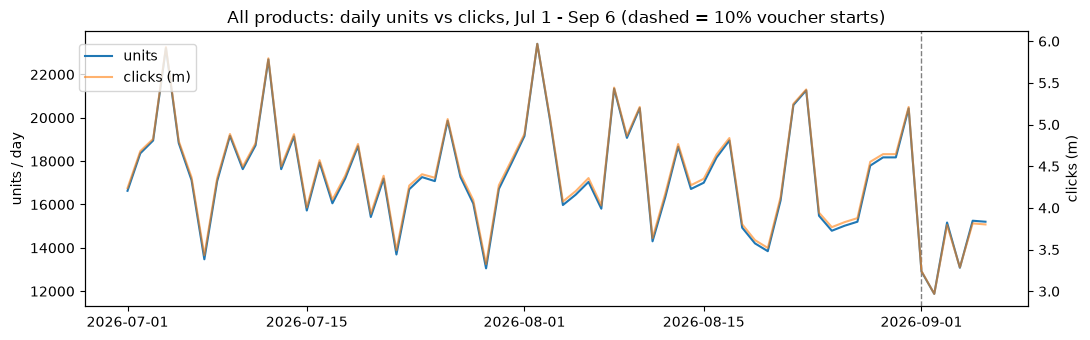

,d,units,clicks,units_per_1k_clicks
54,2026-08-24,15480,3943010.0,3.926
55,2026-08-25,14789,3769210.0,3.924
56,2026-08-26,15020,3829443.0,3.922
57,2026-08-27,15205,3877722.0,3.921
58,2026-08-28,17792,4553049.0,3.908
59,2026-08-29,18173,4644886.0,3.912
60,2026-08-30,18173,4644886.0,3.912
61,2026-08-31,20435,5211270.0,3.921
62,2026-09-01,12911,3244213.0,3.980
63,2026-09-02,11876,2968638.0,4.000


In [26]:
conv_daily = q("""
select d, sum(sales)::int units, sum(clicks) clicks, round(1000 * sum(sales) / sum(clicks), 3) units_per_1k_clicks
from daily where d >= '2026-07-01'
group by 1 order by 1
""")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(conv_daily.d, conv_daily.units, label="units")
ax.set_ylabel("units / day")
ax2 = ax.twinx()
ax2.plot(conv_daily.d, conv_daily.clicks / 1e6, color="tab:orange", alpha=0.6, label="clicks (m)")
ax2.set_ylabel("clicks (m)")
ax.axvline(pd.Timestamp("2026-09-01"), color="grey", ls="--", lw=1)
ax.set_title("All products: daily units vs clicks, Jul 1 - Sep 6 (dashed = 10% voucher starts)")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88))
plt.tight_layout()
plt.show()

conv_daily.tail(14)

In [27]:
q("""
select promotion_name, voucher_rate, active_since::date start_day, active_till::date end_day, count(*) n_products
from src.promotions
group by all
order by start_day, end_day, promotion_name
""")

,promotion_name,voucher_rate,start_day,end_day,n_products
0,Voucher Campaign 10%,0.10,2026-09-01,2026-09-20,3920
1,Voucher Campaign 5%,0.05,2026-09-11,2026-09-16,3920
2,Voucher Campaign 10%,0.10,2026-09-21,2026-10-05,242
3,Voucher Campaign 5%,0.05,2026-09-21,2026-10-05,258


In [28]:
# conversion before vs during the voucher (Sep 1-6 is the only promo period with realised sales)
q("""
select case when d >= '2026-09-01' then 'Sep 1-6 (10% voucher)' else 'Aug 1-31' end period,
       sum(sales)::int units, sum(clicks) clicks,
       round(1000 * sum(sales) / sum(clicks), 3) units_per_1k_clicks
from daily where d >= '2026-08-01'
group by 1 order by 1
""")

,period,units,clicks,units_per_1k_clicks
0,Aug 1-31,544828,139001581.0,3.920
1,Sep 1-6 (10% voucher),83493,20911276.0,3.993


### Findings and rationale

**Cleaning.** Transactions needed the most work. 20k padded and 5k upper-case ids are fixed and kept. 200 test-SKU rows, 50 rows with 1970/2099 timestamps and everything after the cutoff are dropped. 13.7k lines have no product id.

**Duplicates.** 27,370 lines exist exactly twice and are spread evenly over time, so they look like a load issue; one copy is kept. The broken ids have no clean twin and no order line shows up with different content, so after `distinct` nothing is double counted. After cleaning every product has at most one line per day.

**Bad quantities.** 500 negative quantities, 100 placeholders (10000/99999) and 500 lines with qty 1 but returns 5. These are not returns: `returns` is 0 on the negative lines, revenue and cost are normal, and both cost and clicks say the real quantity is about 3. Each of them is the only line for that product-day, so dropping them would create a fake zero. I repair the quantity instead.

**Lost ids are the "zero" days.** Traffic days without a sale match the null-id lines almost one to one per day, in count and in units. So these are real sales with a lost product id, not zero demand. On clean lines, `clicks * product units-per-click` reproduces the recorded quantity exactly, so I use it to fill both the lost lines and the corrupted quantities: about 14.5k of 2.68m product-days (~0.5%), flagged in `sales_source`. The null-id share is stable at ~0.5% per quarter, so it's background noise, not something tied to one period.

**Completeness.** All 721 days are present in transactions and traffic, with no duplicate product-days. The last two weeks before the cutoff have a normal line count, so there's no sign of late-arriving data. Days that look off against the trailing median are weekends (Sunday is the strongest day, Wednesday the weakest) plus three low Wednesdays, and on all of them the units ratio is within 0.03 of the clicks ratio, so they are real, not missing data. No single-product spikes worth treating.

**Availability gaps.** 801 products have no lines and no traffic from 2025-11-25 to 2026-05-23, and their stock snapshots in that window are 0. I treat that as "not online" and leave the days out rather than filling them with 0. One product (`3_x_669814`) was offline Jun 23 – Aug 31 and came back on Sep 1.

**Traffic drives sales.** Product-day correlation between clicks and units is 0.89 in 2026, and units per 1,000 clicks stay between 3.89 and 4.02 in every month. Jul–Aug 2026 is ~30% above Jul–Aug 2025, with clicks up by about the same amount. All clicks are paid and marketing cost follows clicks, so traffic is really a marketing-spend decision.

The traffic table also has rows for Sep 7–20. Those are realised after the cutoff, so I don't use them. That means I have to assume a traffic level for the forecast. My assumption: traffic in Sep 7–20 looks like the recent weeks, i.e. no big change in marketing spend. This is the assumption that matters most.

**Promotions.** Inside the forecast window: a 10% voucher on all 3,920 products for Sep 1–20, and a 5% voucher on all products for Sep 11–16. Both run again from Sep 21 for a few hundred products, outside the window. The table doesn't say whether the vouchers stack on Sep 11–16; I assume a customer gets one voucher, not 15%, and that the plan isn't cancelled. There is no promotion history before Sep 1. In Sep 1–6 conversion went from 3.92 to 3.99 units per 1,000 clicks (+2%) while traffic fell. Six days is thin, so I treat it as weak evidence.

**Stock.** Seven snapshot dates, 1,100 products always null, and for the other 2,800 the value never changes apart from the 0s above. Too sparse for a daily feature; I only use it to explain the availability gap. The 2026-09-11 snapshot is after the cutoff.

**Catalog.** `product_attributes` is one undated snapshot. `cur_gross_red_price` and `avg_historic_sales` could contain information from after a validation origin, so I don't use them as features. I only use attributes that shouldn't change: category, item_role, brand, own brand.

## Part 2: Feature Engineering

Describe the features you choose from the supplied tables and how they support the forecast. See the README for the dataset schema and DuckDB tip.

### 2.1 Setup: one row per product × origin × target day

A forecast is made at an **origin** (the last day of known data) for the next 14 days. Every feature is computed from `daily` up to the origin and is the same for all 14 target days. The model gets `h` (days ahead) and the target weekday so it can still tell the days apart. The same function builds the training rows, the validation rows and the final forecast rows, so they can't drift apart.

Origins are Sundays, because both the validation origin (Aug 23) and the real one (Sep 6) are Sundays:

- **train**: weekly origins 2025-08-10 … 2026-08-09 (53). The last one predicts Aug 10–23, so no training target falls inside the validation window.
- **valid**: origin 2026-08-23, scored on Aug 24 – Sep 6.
- **forecast**: origin 2026-09-06, rows taken from `sample_prediction.csv`.

In [29]:
TRAIN_ORIGINS = list(pd.date_range("2025-08-10", "2026-08-09", freq="7D"))
VALID_ORIGIN = pd.Timestamp("2026-08-23")
FINAL_ORIGIN = pd.Timestamp("2026-09-06")

print(len(TRAIN_ORIGINS), "train origins:", TRAIN_ORIGINS[0].date(), "->", TRAIN_ORIGINS[-1].date(),
      "| last train target:", (TRAIN_ORIGINS[-1] + pd.Timedelta(days=14)).date())

53 train origins: 2025-08-10 -> 2026-08-09 | last train target: 2026-08-23


### 2.2 Promotions as a daily table

Promotions are date ranges and two campaigns overlap on Sep 11–16, so I expand them to days first and keep one row per product-day (highest voucher) before joining. Joining the raw ranges would duplicate those days.

Which campaigns a forecast may see depends on the origin. For the Sep 6 forecast the whole table counts as the known plan (README §2). For historical origins only campaigns already running at the origin are visible (`start_day <= origin`).

In [30]:
con.sql("""
create or replace table promo_days as
select product_id,
       unnest(generate_series(active_since::date, active_till::date, interval 1 day))::date as d,
       voucher_rate, promotion_name, active_since::date as start_day
from src.promotions
where market = 'DE' and channel = 'myshop.de'
""")

q("""
select d, count(*) product_days, max(n) max_campaigns_per_product, max(rate) max_voucher
from (select product_id, d, count(*) n, max(voucher_rate) rate from promo_days group by all)
where d between '2026-09-01' and '2026-09-20'
group by 1 order by 1
""").set_index("d").T

d,2026-09-01,2026-09-02,2026-09-03,2026-09-04,2026-09-05,2026-09-06,2026-09-07,2026-09-08,2026-09-09,2026-09-10,2026-09-11,2026-09-12,2026-09-13,2026-09-14,2026-09-15,2026-09-16,2026-09-17,2026-09-18,2026-09-19,2026-09-20
product_days,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0,3920.0
max_campaigns_per_product,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0
max_voucher,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1


### 2.3 Feature builder

| feature | window (relative to origin) | why |
|---|---|---|
| `mean_7`, `mean_14`, `mean_28`, `mean_56` | last 7 / 14 / 28 / 56 online days | recent level; the short windows react to traffic changes, the long ones are less noisy |
| `std_28` | last 28 days | how stable the product is |
| `n_days_28` | last 28 days | number of online days; flags products just back from a gap (e.g. `3_x_669814` has 6) |
| `dow_factor` | last 56 days | product's average on the target weekday ÷ its overall average. 56 days gives 8 observations per weekday instead of 4 |
| `ly_ratio` | same 14 days last year ÷ the 28 days before that, 364 days back | seasonal direction for this time of year (e.g. summer products fading in September). Missing when last year isn't in the data |
| `h`, `dow` | target day | days ahead, target weekday |
| product attributes | static | `product_category_1/2`, `item_role`, `brand`, `is_own_brand`, `seasonality`; lets products borrow from similar ones |
| `voucher_rate` | target day, plan known at origin | built and checked, but not a model input (see 2.5) |
| `baseline` | | `mean_28 × dow_factor`, the baseline forecast for Part 3, also given to the model as a feature |

Not used: clicks (the Sep 7–20 values are after the cutoff, and recent clicks don't remove the traffic assumption), price and `avg_historic_sales` (undated snapshot, possible leakage), stock (constant).

In [31]:
CAT_COLS = ["product_category_1", "product_category_2", "item_role", "brand", "seasonality"]

attrs = q("select product_id, product_category_1, product_category_2, item_role, brand, is_own_brand::int as is_own_brand, seasonality from src.product_attributes")
for c in CAT_COLS:
    attrs[c] = attrs[c].astype("category")
attrs["is_cohort"] = (attrs.item_role == "Focus article") & (attrs.product_category_2 == "Tops")


def build_features(origins, keep_unknown_target=False):
    con.register("origins_df", pd.DataFrame({"origin": pd.to_datetime(origins)}))
    con.sql("create or replace temp table origins as select origin::date as origin from origins_df")

    df = q(f"""
    with hist as (
        select o.origin, x.product_id,
               avg(x.sales) filter (where x.d > o.origin - 7)  as mean_7,
               avg(x.sales) filter (where x.d > o.origin - 14) as mean_14,
               avg(x.sales) filter (where x.d > o.origin - 28) as mean_28,
               avg(x.sales)                                    as mean_56,
               stddev_samp(x.sales) filter (where x.d > o.origin - 28) as std_28,
               count(*) filter (where x.d > o.origin - 28)     as n_days_28
        from origins o
        join daily x on x.d > o.origin - 56 and x.d <= o.origin
        group by all
    ),
    dow_mean as (
        select o.origin, x.product_id, isodow(x.d) as dow, avg(x.sales) as dow_mean
        from origins o
        join daily x on x.d > o.origin - 56 and x.d <= o.origin
        group by all
    ),
    last_year as (
        select o.origin, x.product_id,
               avg(x.sales) filter (where x.d > o.origin - 364) as ly_next14,
               avg(x.sales) filter (where x.d <= o.origin - 364) as ly_prev28
        from origins o
        join daily x on x.d > o.origin - 392 and x.d <= o.origin - 350
        group by all
    ),
    promo as (
        select o.origin, p.product_id, p.d, max(p.voucher_rate) as voucher_rate
        from origins o
        join promo_days p on p.d > o.origin and p.d <= o.origin + 14
        where p.start_day <= o.origin or o.origin >= date '{FINAL_ORIGIN.date()}'
        group by all
    ),
    grid as (
        select o.origin, a.product_id, r.h::int as h, o.origin + r.h::int as target_date
        from origins o
        cross join (select product_id from src.product_attributes) a
        cross join range(1, 15) r(h)
    )
    select g.origin, g.product_id, g.h, g.target_date, isodow(g.target_date) as dow,
           hi.mean_7, hi.mean_14, hi.mean_28, hi.mean_56, hi.std_28,
           coalesce(hi.n_days_28, 0) as n_days_28,
           coalesce(dm.dow_mean / nullif(hi.mean_56, 0), 1) as dow_factor,
           ly.ly_next14 / nullif(ly.ly_prev28, 0) as ly_ratio,
           coalesce(pr.voucher_rate, 0) as voucher_rate,
           coalesce(hi.mean_28, hi.mean_56, 0) * coalesce(dm.dow_mean / nullif(hi.mean_56, 0), 1) as baseline,
           y.sales as target, y.sales_source as target_source
    from grid g
    left join hist hi       on hi.origin = g.origin and hi.product_id = g.product_id
    left join dow_mean dm   on dm.origin = g.origin and dm.product_id = g.product_id and dm.dow = isodow(g.target_date)
    left join last_year ly  on ly.origin = g.origin and ly.product_id = g.product_id
    left join promo pr      on pr.origin = g.origin and pr.product_id = g.product_id and pr.d = g.target_date
    left join daily y       on y.product_id = g.product_id and y.d = g.target_date
    {"" if keep_unknown_target else "where y.sales is not null"}
    order by g.origin, g.product_id, g.h
    """)

    num = df.select_dtypes("number").columns.drop(["h", "dow", "n_days_28"])
    df[num] = df[num].astype("float32")
    return df.merge(attrs, on="product_id", how="left")

In [32]:
train = build_features(TRAIN_ORIGINS)
valid = build_features([VALID_ORIGIN])
fcst = build_features([FINAL_ORIGIN], keep_unknown_target=True)

pd.DataFrame({
    name: {"rows": len(df), "origins": df.origin.nunique(), "products": df.product_id.nunique(),
           "first_target": df.target_date.min().date(), "last_target": df.target_date.max().date(),
           "rows_repaired_target": int(df.target_source.fillna("").str.startswith("repaired").sum()),
           "MB": round(df.memory_usage(deep=True).sum() / 1e6)}
    for name, df in [("train", train), ("valid", valid), ("forecast", fcst)]
}).T

,rows,origins,products,first_target,last_target,rows_repaired_target,MB
train,2620163,53,3920,2025-08-11,2026-08-23,14155,304
valid,54872,1,3920,2026-08-24,2026-09-06,298,6
forecast,54880,1,3920,2026-09-07,2026-09-20,0,7


### 2.4 Checks

- no target day on or before its origin, and no training target inside the validation window
- one product recomputed by hand from `daily` to confirm the windows stop at the origin
- forecast rows match `sample_prediction.csv` exactly
- missing values per feature

In [33]:
assert (train.target_date > train.origin).all() and (valid.target_date > valid.origin).all()
assert train.target_date.max() <= VALID_ORIGIN, "training target inside the validation window"
assert not train.duplicated(["origin", "product_id", "h"]).any()

# recompute the Aug 23 features for one cohort product straight from daily
pid = valid.loc[valid.is_cohort, "product_id"].iloc[0]
hist = q(f"select d, sales from daily where product_id = '{pid}' and d <= date '{VALID_ORIGIN.date()}' order by d")
hist["d"] = pd.to_datetime(hist.d)
last56 = hist[hist.d > VALID_ORIGIN - pd.Timedelta(days=56)]
by_hand = {
    "mean_7": last56[last56.d > VALID_ORIGIN - pd.Timedelta(days=7)].sales.mean(),
    "mean_28": last56[last56.d > VALID_ORIGIN - pd.Timedelta(days=28)].sales.mean(),
    "mean_56": last56.sales.mean(),
    "dow_factor_sun": last56[last56.d.dt.day_of_week == 6].sales.mean() / last56.sales.mean(),
    "last_day_used": last56.d.max().date(),
}
row = valid[(valid.product_id == pid) & (valid.dow == 7)].iloc[0]
pd.DataFrame({"by_hand": by_hand,
              "feature_table": {"mean_7": row.mean_7, "mean_28": row.mean_28, "mean_56": row.mean_56,
                                "dow_factor_sun": row.dow_factor, "last_day_used": VALID_ORIGIN.date()}})

,by_hand,feature_table
mean_7,2.285714,2.285714
mean_28,2.285714,2.285714
mean_56,2.357143,2.357143
dow_factor_sun,1.219697,1.219697
last_day_used,2026-08-23,2026-08-23


In [34]:
sample = pd.read_csv("sample_prediction.csv", dtype={"product_id": str}, parse_dates=["date"])
keys = fcst[["product_id", "target_date"]].rename(columns={"target_date": "date"})
check = sample[["product_id", "date"]].merge(keys, how="outer", indicator=True)
print(check._merge.value_counts().to_dict())
assert (check._merge == "both").all() and len(fcst) == len(sample) == 54880

{'both': 54880, 'left_only': 0, 'right_only': 0}


In [35]:
FEATURES = ["h", "dow", "mean_7", "mean_14", "mean_28", "mean_56", "std_28", "n_days_28",
            "dow_factor", "ly_ratio", "baseline", "is_own_brand"] + CAT_COLS

pd.DataFrame({
    name: df[FEATURES].isna().mean().round(4)
    for name, df in [("train", train), ("valid", valid), ("forecast", fcst)]
}).query("train > 0 or valid > 0 or forecast > 0")

,train,valid,forecast
mean_7,0.0028,0.0001,0.0
mean_14,0.0028,0.0001,0.0
mean_28,0.0028,0.0001,0.0
mean_56,0.0028,0.0001,0.0
std_28,0.0070,0.0001,0.0
ly_ratio,0.1257,0.0000,0.0


### 2.5 Why the promotion isn't a model feature

In [36]:
pd.DataFrame({
    name: {"rows_with_voucher": int((df.voucher_rate > 0).sum()),
           "share": round((df.voucher_rate > 0).mean(), 3),
           "max_voucher": float(df.voucher_rate.max())}
    for name, df in [("train", train), ("valid", valid), ("forecast", fcst)]
}).T

,rows_with_voucher,share,max_voucher
train,0.0,0.0,0.0
valid,0.0,0.0,0.0
forecast,54880.0,1.0,0.1


Under the "known at origin" rule the voucher is 0 in every training and validation row: the only campaign with realised sales started on Sep 1, after the Aug 23 origin. A tree model can't learn anything from a column that never changes, and at forecast time it would just ignore it. Even if I relaxed the rule and let the final model see Sep 1–6, that's six days, every product at 10%, on the same days traffic dropped, so the effect can't be separated from traffic.

So the voucher goes in as an explicit adjustment after the model, based on the one piece of evidence there is: units per 1,000 clicks rose from 3.92 in August to 3.99 in Sep 1–6 (+2%, section 1.7). I'll report the forecast with and without it. Sep 7–20 is fully inside the 10% campaign; with my no-stacking assumption Sep 11–16 gets the same adjustment.

### Features and rationale

- Each row is (product, origin, target day). All features come from data up to the origin and are reused for all 14 days, so producing the 14-day forecast never needs a value from inside the forecast window. The same builder makes train, validation and forecast rows.
- **Level**: means over 7 / 14 / 28 / 56 days. Sales are basically clicks × a stable conversion rate, so the recent level carries most of the signal, and using recent data means I'm assuming traffic stays roughly where it has been.
- **Weekly shape**: `dow_factor` per product over 56 days, plus target `dow` and `h`.
- **Season**: `ly_ratio`, last year's change over the same two weeks. It's missing for origins before Oct 2025 (no data a year earlier); LightGBM handles missing values.
- **Availability**: `n_days_28` so the model knows when the recent means rest on only a few days.
- **Product**: static catalog attributes only.
- **Baseline as a feature**: `mean_28 × dow_factor`, so the model starts from the baseline and learns corrections.
- **Left out**: clicks, price / `avg_historic_sales`, stock, and the voucher (adjustment instead, 2.5).
- Repaired targets are kept but labelled (`target_source`), so I can check in Part 4 whether they change the result.

## Part 3: Predictive Modeling

Compare a simple baseline with one proposed approach on a full historical 14-day forecast window. Explain your multi-day forecasting strategy and how you avoid using information from inside the validation window.

### 3.1 Two windows: one to choose, one to report

I tried four candidates against the baseline. If I picked the winner on the same window I report, the reported number would flatter it. So:

- **selection window**: origin 2026-08-09, scored on Aug 10–23. Train only on targets up to Aug 9. The model is chosen here.
- **test window**: origin 2026-08-23, scored on Aug 24 – Sep 6. Train on targets up to Aug 23. This is the "full historical 14-day window" for Part 4.

**How the 14 days are produced (direct strategy).** Every row is (product, origin, target day). The features are frozen at the origin and `h` = days ahead is a feature, so one model predicts day 1 and day 14 in one pass. No prediction is fed back in as an input and no sales from inside the window are used. The time-series model (NHITS) is fitted on history up to the origin and asked for the next 14 days.

In [37]:
import time
import logging
import warnings
from pathlib import Path

import lightgbm as lgb
import xgboost as xgb
import matplotlib.dates as mdates
from sklearn.ensemble import HistGradientBoostingRegressor

SELECT_ORIGIN = pd.Timestamp("2026-08-09")
sel = build_features([SELECT_ORIGIN])
WINDOWS = {"select": (SELECT_ORIGIN, sel), "test": (VALID_ORIGIN, valid)}

for w, (origin, ev) in WINDOWS.items():
    tr = train[train.target_date <= origin]
    assert tr.target_date.max() <= origin < ev.target_date.min()
    print(f"{w:6s} origin {origin.date()} | scored {ev.target_date.min().date()} -> {ev.target_date.max().date()}, "
          f"{len(ev):,} rows | train {len(tr):,} rows, last target {tr.target_date.max().date()}")


def metrics(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    total = y.sum()
    return {"WAPE": np.abs(y - yhat).sum() / total if total > 0 else np.nan,
            "MAE": np.abs(y - yhat).mean(),
            "RMSE": np.sqrt(((y - yhat) ** 2).mean()),
            "bias": (yhat.sum() - total) / total if total > 0 else np.nan}

select origin 2026-08-09 | scored 2026-08-10 -> 2026-08-23, 54,866 rows | train 2,537,864 rows, last target 2026-08-09
test   origin 2026-08-23 | scored 2026-08-24 -> 2026-09-06, 54,872 rows | train 2,620,163 rows, last target 2026-08-23


### 3.2 Candidates

| model | type | what it sees |
|---|---|---|
| **baseline** | rule | `mean_28 × dow_factor` (Part 2) |
| **LightGBM** | global tree model, Tweedie loss | the Part 2 feature table |
| **XGBoost** | global tree model, Tweedie loss | same features, same rows |
| **gradient boost** | scikit-learn `HistGradientBoostingRegressor`, Poisson loss | same features, same rows |
| **NHITS** | global neural net (neuralforecast) | last 56 days of each series, 14 days out |

Tweedie and Poisson losses suit daily counts: never negative, many small values, a long right tail. scikit-learn's gradient boosting has no Tweedie option, so it gets Poisson. I use the histogram version because the classic `GradientBoostingRegressor` takes hours on 2.6m rows. The tree models get fixed settings with no tuning on either window. NHITS needs `requirements-extra.txt` and takes 10–13 min per window on CPU.

Every model's predictions are cached in `model_runs/`; delete the folder to refit everything.

Not included: Prophet. It fits one model per product. A run on 500 products took ~400 s per window, so the full catalog would take ~50 min per window, which doesn't fit the 3-hour limit. In that trial run (not kept in the notebook) it was worse than the baseline on both windows.

In [38]:
RUNS = Path("model_runs")
RUNS.mkdir(exist_ok=True)


def cached(name, fn):
    f = RUNS / f"{name}.parquet"
    if not f.exists():
        t = time.time()
        out = fn()
        out["fit_s"] = round(time.time() - t)
        out.to_parquet(f)
    return pd.read_parquet(f)


def as_frame(ev, pred):
    return pd.DataFrame({"product_id": ev.product_id.values,
                         "target_date": pd.to_datetime(ev.target_date).values, "pred": pred})


LGB_PARAMS = dict(objective="tweedie", tweedie_variance_power=1.2, n_estimators=500, learning_rate=0.05,
                  num_leaves=63, min_child_samples=200, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                  random_state=7, deterministic=True, force_row_wise=True, verbose=-1)
XGB_PARAMS = {"objective": "reg:tweedie", "tweedie_variance_power": 1.2, "tree_method": "hist", "max_depth": 8,
              "eta": 0.05, "subsample": 0.8, "colsample_bytree": 0.8, "min_child_weight": 50, "seed": 7}
XGB_ROUNDS = 500
GBM_PARAMS = dict(loss="poisson", learning_rate=0.05, max_iter=500, max_leaf_nodes=63, min_samples_leaf=200,
                  categorical_features="from_dtype", early_stopping=False, random_state=7)


def run_lightgbm(origin, ev):
    tr = train[train.target_date <= origin]
    model = lgb.LGBMRegressor(**LGB_PARAMS).fit(tr[FEATURES], tr.target)
    return as_frame(ev, model.predict(ev[FEATURES]))


def run_xgboost(origin, ev):
    tr = train[train.target_date <= origin]
    booster = xgb.train(XGB_PARAMS, xgb.DMatrix(tr[FEATURES], tr.target, enable_categorical=True), XGB_ROUNDS)
    return as_frame(ev, booster.predict(xgb.DMatrix(ev[FEATURES], enable_categorical=True)))


def run_gradient_boost(origin, ev):
    tr = train[train.target_date <= origin]
    model = HistGradientBoostingRegressor(**GBM_PARAMS).fit(tr[FEATURES], tr.target)
    return as_frame(ev, model.predict(ev[FEATURES]))

In [39]:
def run_nhits(origin):
    warnings.filterwarnings("ignore")
    for name in ("pytorch_lightning", "lightning", "lightning.pytorch", "lightning_fabric"):
        logging.getLogger(name).setLevel(logging.ERROR)
    from neuralforecast import NeuralForecast
    from neuralforecast.models import NHITS
    from neuralforecast.losses.pytorch import MSE

    # full calendar per product; offline days are 0 with available_mask = 0 so they don't count in the loss
    series = q(f"""
    select p.product_id as unique_id, c.d::timestamp as ds, coalesce(x.sales, 0)::double as y,
           (x.sales is not null)::int as available_mask
    from (select distinct product_id from daily) p
    cross join (select unnest(generate_series((select min(d) from daily), date '{origin.date()}', interval 1 day))::date as d) c
    left join daily x on x.product_id = p.product_id and x.d = c.d
    order by 1, 2
    """)
    model = NHITS(h=14, input_size=56, loss=MSE(), scaler_type="standard", max_steps=1000, batch_size=256,
                  windows_batch_size=1024, learning_rate=1e-3, random_seed=7, accelerator="cpu",
                  enable_progress_bar=False, enable_model_summary=False, logger=False, enable_checkpointing=False)
    nf = NeuralForecast(models=[model], freq="D")
    nf.fit(series)
    p = nf.predict()
    return pd.DataFrame({"product_id": p.unique_id.values, "target_date": pd.to_datetime(p.ds).values,
                         "pred": p.NHITS.clip(lower=0).values})

In [40]:
runs = {}
for w, (origin, ev) in WINDOWS.items():
    runs[(w, "lightgbm")] = cached(f"{w}_lightgbm", lambda: run_lightgbm(origin, ev))
    runs[(w, "xgboost")] = cached(f"{w}_xgboost", lambda: run_xgboost(origin, ev))
    runs[(w, "gradient_boost")] = cached(f"{w}_gradient_boost", lambda: run_gradient_boost(origin, ev))
    runs[(w, "nhits")] = cached(f"{w}_nhits", lambda: run_nhits(origin))

MODELS = ["lightgbm", "xgboost", "gradient_boost", "nhits"]
scored = {}
for w, (origin, ev) in WINDOWS.items():
    s = ev[["product_id", "target_date", "target", "target_source", "is_cohort", "baseline"]].copy()
    s["target_date"] = pd.to_datetime(s.target_date)
    for m in MODELS:
        s = s.merge(runs[(w, m)][["product_id", "target_date", "pred"]].rename(columns={"pred": m}),
                    on=["product_id", "target_date"], how="left")
    scored[w] = s

pd.DataFrame({w: {m: f"{int(runs[(w, m)].fit_s.iloc[0])} s, {len(runs[(w, m)]):,} rows" for m in MODELS} for w in WINDOWS})

,select,test
lightgbm,"61 s, 54,866 rows","96 s, 54,872 rows"
xgboost,"148 s, 54,866 rows","195 s, 54,872 rows"
gradient_boost,"219 s, 54,866 rows","177 s, 54,872 rows"
nhits,"765 s, 54,880 rows","613 s, 54,880 rows"


### 3.3 Results

WAPE and bias are fractions of actual units (bias > 0 = over-forecast). All 3,920 products, same rows for every model.

In [41]:
def compare(models):
    out = {}
    for w, s in scored.items():
        for scope, part in [("all", s), ("cohort", s[s.is_cohort])]:
            for m in models:
                r = metrics(part.target, part[m])
                out.setdefault(m, {})[(w, scope, "WAPE")] = r["WAPE"]
                out.setdefault(m, {})[(w, scope, "bias")] = r["bias"]
    return pd.DataFrame(out).T.round(4)


compare(["baseline", *MODELS])

select                            test                        
                   all          cohort             all          cohort        
                  WAPE    bias    WAPE    bias    WAPE    bias    WAPE    bias
baseline        0.1235  0.0113  0.1609  0.0391  0.2243  0.1227  0.1662  0.0931
lightgbm        0.1071  0.0406  0.1366  0.0042  0.2129  0.1047  0.1449  0.0704
xgboost         0.1072  0.0363  0.1291  0.0009  0.2260  0.1061  0.1427  0.0618
gradient_boost  0.1082  0.0393  0.1397  0.0089  0.2123  0.1010  0.1460  0.0657
nhits           0.1463  0.0643  0.1319 -0.0122  0.2015  0.0965  0.1848  0.1053

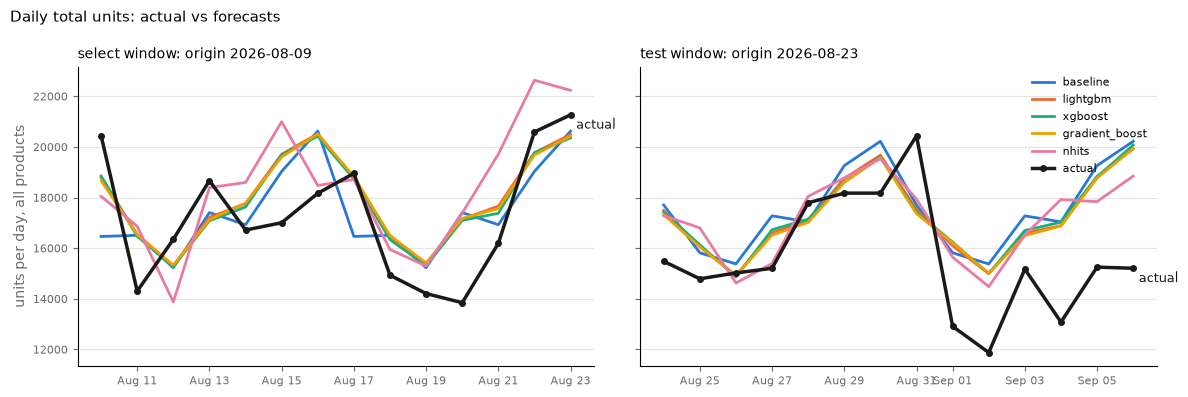

In [42]:
COLORS = {"baseline": "#2a78d6", "lightgbm": "#eb6834", "xgboost": "#1baf7a", "gradient_boost": "#eda100", "nhits": "#e87ba4"}
INK, MUTED = "#1a1a19", "#6b6a64"

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (w, s) in zip(axes, scored.items()):
    tot = s.groupby("target_date")[["target", *COLORS]].sum()
    for m, c in COLORS.items():
        ax.plot(tot.index, tot[m], color=c, lw=2, label=m)
    ax.plot(tot.index, tot.target, color=INK, lw=2.5, marker="o", ms=4, label="actual")
    ax.annotate("actual", (tot.index[-1], tot.target.iloc[-1]), xytext=(4, -10), textcoords="offset points", color=INK, fontsize=9)
    ax.set_title(f"{w} window: origin {WINDOWS[w][0].date()}", loc="left", fontsize=10)
    ax.tick_params(colors=MUTED, labelsize=8)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
axes[0].set_ylabel("units per day, all products", color=MUTED)
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Daily total units: actual vs forecasts", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

In [43]:
best = compare(["baseline", *MODELS])[("select", "all", "WAPE")].sort_values()
print("selection window WAPE, full catalog:")
print(best.to_string())

selection window WAPE, full catalog:
lightgbm          0.1071
xgboost           0.1072
gradient_boost    0.1082
baseline          0.1235
nhits             0.1463


### Model and validation

- **Set-up.** Direct multi-horizon forecasting: one row per (product, origin, target day), features frozen at the origin, `h` as a feature, so all 14 days come out of one pass without any value from inside the window. The model is chosen on the Aug 10–23 window and reported on Aug 24 – Sep 6, each trained only on targets up to its own origin.
- **Selection window (Aug 10–23).** LightGBM has the lowest WAPE (0.1071), just ahead of XGBoost (0.1072) and gradient boost (0.1082), and 13.3% better than the baseline (0.1235). NHITS (0.1463) is worse than the baseline.
- **Choice: LightGBM.** It wins on the selection window and was the model I planned in Part 2. The three tree models are within 0.0011 of each other, so they are effectively equal. NHITS swings between windows (worst on selection, best overall on test, worst on the test cohort) and costs 10–13 min per fit. One good window isn't enough reason to pick it.
- **Test window (Aug 24 – Sep 6).** LightGBM 0.2129 vs baseline 0.2243 overall, 0.1449 vs 0.1662 on the cohort. Here gradient boost is marginally better overall (0.2123), XGBoost on the cohort (0.1427), and NHITS best overall (0.2015). I don't switch: the choice was made on the selection window, and re-picking on the window I report would inflate the result. Every model over-forecasts by 10–12%. Total sales fell in late August, and nothing known at the Aug 23 origin showed it (Part 1: sales track clicks, and clicks dropped). This is the planner's question, picked up in Part 4.
- **What I'd do with more time:** add recent clicks as a feature with an explicit traffic scenario for the forecast window, and check the choice on more than one selection window.

## Part 4: Forecast Evaluation & Merchandise Planner Investigation

Report WAPE, MAE, RMSE, and forecast bias for both approaches, overall and for the investigation cohort. State your metric conventions and zero-denominator handling.

Investigate the Focus article / Tops cohort question in the README. Include executable DuckDB SQL and its output, a compact table or chart, at least two plausible explanations, and a small sensitivity check. Separate observations from interpretations and assumptions.

### 4.1 Baseline vs LightGBM

Conventions:
- WAPE = Σ|y − ŷ| / Σy and bias = (Σŷ − Σy) / Σy, both as **fractions**; bias > 0 means over-forecast.
- MAE and RMSE are in units per product-day.
- If Σy = 0, WAPE and bias are returned as NaN rather than 0 or ∞. That doesn't happen here: the smallest total scored is the cohort in one window, about 1,100 units.
- A product-day is scored only if it has an actual. That leaves out 8 test-window days for `3_x_669814`, which was offline until Aug 31.

The test window (Aug 24 – Sep 6) is the reported result. The selection window is shown for reference.

In [44]:
rows = {}
for w, s in scored.items():
    for scope, part in [("all", s), ("cohort", s[s.is_cohort])]:
        for m in ["baseline", "lightgbm"]:
            rows[(w, scope, m)] = metrics(part.target, part[m]) | {
                "actual_units": part.target.sum(), "forecast_units": part[m].sum(), "rows": len(part)}
eval_table = pd.DataFrame(rows).T.rename_axis(["window", "scope", "model"])
eval_table[["WAPE", "MAE", "RMSE", "bias"]] = eval_table[["WAPE", "MAE", "RMSE", "bias"]].astype(float).round(4)
eval_table[["actual_units", "forecast_units", "rows"]] = eval_table[["actual_units", "forecast_units", "rows"]].astype(float).round(0).astype(int)
eval_table.loc[["test", "select"]]

WAPE     MAE    RMSE    bias  actual_units  forecast_units   rows
window scope  model                                                                        
test   all    baseline  0.2243  0.8934  1.4231  0.1227        218560          245384  54872
              lightgbm  0.2129  0.8480  1.3289  0.1047        218560          241433  54872
       cohort baseline  0.1662  0.3569  0.4449  0.0931          1112            1216    518
              lightgbm  0.1449  0.3111  0.3957  0.0704          1112            1190    518
select all    baseline  0.1235  0.5441  0.7508  0.0113        241626          244363  54866
              lightgbm  0.1071  0.4715  0.6365  0.0406        241626          251437  54866
       cohort baseline  0.1609  0.3693  0.4443  0.0391          1189            1236    518
              lightgbm  0.1366  0.3134  0.3929  0.0042          1189            1194    518

### 4.2 Is the cohort really lower?

Cohort: `item_role = 'Focus article' AND product_category_2 = 'Tops'`. P1 = Aug 10–23 and P2 = Aug 24 – Sep 6. Both are 14 days with two of each weekday, so the weekday mix is the same in both. Sales come from `daily` (Part 1): cleaned, deduplicated, ids fixed, lost-id days repaired.

In [45]:
con.sql("""
create or replace temp view cohort as
select product_id from src.product_attributes
where item_role = 'Focus article' and product_category_2 = 'Tops'
""")
con.sql("""
create or replace macro period(d) as
    case when d between date '2026-08-10' and date '2026-08-23' then 'P1 Aug 10-23'
         when d between date '2026-08-24' and date '2026-09-06' then 'P2 Aug 24-Sep 6' end
""")

check = q("""
select period(d) as period,
       (select count(*) from cohort) as cohort_products,
       count(distinct product_id) as products_online,
       count(*) as product_days,
       sum(sales)::int as units,
       sum(sales) filter (where sales_source <> 'recorded')::int as units_repaired
from daily join cohort using (product_id)
where period(d) is not null
group by 1 order by 1
""")
check["change_vs_p1"] = (check.units / check.units.iloc[0] - 1).round(4)
check

,period,cohort_products,products_online,product_days,units,units_repaired,change_vs_p1
0,P1 Aug 10-23,37,37,518,1189,10,0.0000
1,P2 Aug 24-Sep 6,37,37,518,1112,10,-0.0648


Does the drop depend on my cleaning? Here is the same comparison on four versions of the data. The last two are what a direct query on the raw table would give.

In [46]:
q("""
with raw as (
    select time::date as d, lower(trim(product_id)) as fixed_id, product_id as raw_id, sales_before_returns as units
    from src.transactions
    where market = 'DE' and channel = 'myshop.de' and period(time::date) is not null
),
versions as (
    select 'cleaned, repaired days included (used)' as version, period(d) as period, sales as units
    from daily join cohort using (product_id) where period(d) is not null
    union all
    select 'cleaned, recorded lines only', period(d), sales
    from daily join cohort using (product_id) where period(d) is not null and sales_source = 'recorded'
    union all
    select 'raw, ids fixed, no dedup, bad qty kept', period(d), units
    from raw where fixed_id in (select product_id from cohort)
    union all
    select 'raw, exact id match only', period(d), units
    from raw where raw_id in (select product_id from cohort)
)
select version,
       sum(units) filter (where period like 'P1%') as p1_units,
       sum(units) filter (where period like 'P2%') as p2_units,
       round(p2_units / p1_units - 1, 4) as change
from versions
group by 1 order by 1
""")

,version,p1_units,p2_units,change
0,"cleaned, recorded lines only",1179.0,1102.0,-0.0653
1,"cleaned, repaired days included (used)",1189.0,1112.0,-0.0648
2,"raw, exact id match only",1181.0,1104.0,-0.0652
3,"raw, ids fixed, no dedup, bad qty kept",1185.0,1116.0,-0.0582


### 4.3 Possible explanations

Every table here is used at product-day grain. Traffic is daily per product (`active_since::date`). Promotions are expanded to one row per product-day (`promo_days`, Part 2). Stock has only 7 snapshot dates, so it can only rule things out, not track a trend. Dated prices don't exist, but the transaction lines carry revenue, discounts and vouchers per unit.

**E1. Less traffic.** Sales in this shop are clicks × a stable conversion rate (Part 1). If clicks fell and conversion didn't, the drop comes from traffic.

In [47]:
e1 = q("""
select period(d) as period,
       sum(clicks)::int as clicks,
       round(sum(marketing_cost)) as marketing_cost,
       sum(sales)::int as units,
       round(1000 * sum(sales) / sum(clicks), 3) as units_per_1k_clicks,
       round(sum(marketing_cost) / sum(clicks), 4) as cost_per_click
from daily join cohort using (product_id)
where period(d) is not null
group by 1 order by 1
""")
e1

,period,clicks,marketing_cost,units,units_per_1k_clicks,cost_per_click
0,P1 Aug 10-23,135854,879.0,1189,8.752,0.0065
1,P2 Aug 24-Sep 6,127056,826.0,1112,8.752,0.0065


**E2. End of summer.** All 37 cohort products have `seasonality = 'Summer'`. If the drop is seasonal, the same weeks last year should show it, and other Summer products should drop more than non-Summer ones. 2025 is shifted by 364 days so the weekdays line up.

In [48]:
e2 = q("""
with x as (
    select product_id, sales, clicks, period(d) as period, 2026 as year from daily where period(d) is not null
    union all
    select product_id, sales, clicks, period(d + 364), 2025 from daily where period(d + 364) is not null
)
select case when c.product_id is not null then 'cohort (all Summer)'
            when a.seasonality = 'Summer' then 'other Summer products'
            else 'non-Summer products' end as product_group,
       year,
       count(distinct x.product_id) as products,
       sum(sales) filter (where period like 'P1%')::int as p1_units,
       sum(sales) filter (where period like 'P2%')::int as p2_units,
       round(p2_units / p1_units - 1, 4) as change,
       round(sum(clicks) filter (where period like 'P2%') / sum(clicks) filter (where period like 'P1%') - 1, 4) as clicks_change
from x
join src.product_attributes a using (product_id)
left join cohort c using (product_id)
group by all order by 1, 2
""")
e2

,product_group,year,products,p1_units,p2_units,change,clicks_change
0,cohort (all Summer),2025,37,1265,1231,-0.0269,-0.0264
1,cohort (all Summer),2026,37,1189,1112,-0.0648,-0.0648
2,non-Summer products,2025,2965,144804,140911,-0.0269,-0.0267
3,non-Summer products,2026,2965,181621,168545,-0.0720,-0.0775
4,other Summer products,2025,918,43213,40437,-0.0642,-0.0630
5,other Summer products,2026,918,58816,48903,-0.1685,-0.1754


**E3. A promotion ended / E5. Price went up.** If P1 had a promotion or lower prices, P2 would look weak next to it. I checked the promotions table, then revenue, red-price discount and voucher spend per unit on the cohort's transaction lines.

In [49]:
e3 = q("""
select p.period, count(pd.d) as promo_product_days, max(pd.voucher_rate) as max_voucher, min(pd.d) as first_promo_day
from (values ('P1 Aug 10-23'), ('P2 Aug 24-Sep 6')) p(period)
left join (select * from promo_days join cohort using (product_id)) pd on period(pd.d) = p.period
group by 1 order by 1
""")
e5 = q("""
select period(time::date) as period,
       sum(sales_before_returns)::int as units_on_clean_lines,
       round(sum(revenue) / sum(sales_before_returns), 2) as revenue_per_unit,
       round(sum(red_price_discount_spending) / sum(sales_before_returns), 3) as red_price_discount_per_unit,
       round(sum(voucher_spending) / sum(sales_before_returns), 3) as voucher_per_unit,
       round(sum(profit) / sum(sales_before_returns), 2) as profit_per_unit,
       round(sum(purchase_cost) / sum(sales_before_returns), 2) as purchase_cost_per_unit
from (select distinct * from src.transactions) t
where market = 'DE' and channel = 'myshop.de'
  and lower(trim(product_id)) in (select product_id from cohort)
  and sales_before_returns between 1 and 999 and returns <= sales_before_returns
  and period(time::date) is not null
group by 1 order by 1
""")
display(e3)
e5

,period,promo_product_days,max_voucher,first_promo_day
0,P1 Aug 10-23,0,NaN,NaT
1,P2 Aug 24-Sep 6,222,0.1,2026-09-01


,period,units_on_clean_lines,revenue_per_unit,red_price_discount_per_unit,voucher_per_unit,profit_per_unit,purchase_cost_per_unit
0,P1 Aug 10-23,1179,13.23,0.004,0.850,9.33,2.06
1,P2 Aug 24-Sep 6,1102,12.42,0.005,0.677,8.68,1.97


**E4. Products not available.** Fewer products online or stock-outs in P2 would cut sales without any change in demand.

In [50]:
e4 = q("""
select active_since as snapshot, count(*) as products,
       count(*) filter (where stock_start_of_day = 0) as zero_stock,
       count(stock_start_of_day) as non_null,
       round(avg(end_liquidation_value), 2) as avg_liquidation_value
from src.stock join cohort using (product_id)
where market = 'DE' and channel = 'myshop.de' and active_since <= date '2026-09-06'
group by 1 order by 1
""")
e4

,snapshot,products,zero_stock,non_null,avg_liquidation_value
0,2023-12-26,37,0,37,0.87
1,2025-11-25,37,37,37,0.87
2,2026-04-24,37,37,37,0.87
3,2026-05-24,37,0,37,0.87
4,2026-06-23,37,0,37,0.87
5,2026-09-01,37,0,37,0.87


**Summary table.**

In [51]:
def pct(a, b):
    return f"{b / a - 1:+.1%}"


p1, p2 = check.iloc[0], check.iloc[1]
c25 = e2[(e2.product_group == "cohort (all Summer)") & (e2.year == 2025)].iloc[0]
oth = e2[e2.year == 2026].set_index("product_group").change
summary = pd.DataFrame([
    ["observed", "cohort units", f"{p1.units:,}", f"{p2.units:,}", pct(p1.units, p2.units), "the drop is real"],
    ["E1 less traffic", "cohort clicks", f"{e1.clicks[0]:,}", f"{e1.clicks[1]:,}", pct(e1.clicks[0], e1.clicks[1]),
     "supports: clicks fall as much as units"],
    ["E1 less traffic", "units per 1k clicks", e1.units_per_1k_clicks[0], e1.units_per_1k_clicks[1],
     pct(e1.units_per_1k_clicks[0], e1.units_per_1k_clicks[1]), "conversion unchanged"],
    ["E2 end of summer", "cohort units, same weeks 2025", f"{c25.p1_units:,}", f"{c25.p2_units:,}", pct(c25.p1_units, c25.p2_units),
     "partly: there is a seasonal dip, but smaller"],
    ["E2 end of summer", "other products 2026 (Summer / non-Summer)", "", "",
     f"{oth['other Summer products']:+.1%} / {oth['non-Summer products']:+.1%}",
     "supports: Summer products fell most this year"],
    ["E3 promotion ended", "cohort promo product-days", e3.promo_product_days[0], e3.promo_product_days[1], "",
     "contradicts: P1 had none, voucher starts Sep 1 in P2"],
    ["E4 availability", "online product-days", p1.product_days, p2.product_days, pct(p1.product_days, p2.product_days),
     "contradicts: all online, no zero stock since May"],
    ["E5 price up", "revenue per unit", e5.revenue_per_unit[0], e5.revenue_per_unit[1], pct(e5.revenue_per_unit[0], e5.revenue_per_unit[1]),
     "contradicts: no price rise, discounts ~0"],
], columns=["explanation", "measure", "P1 Aug 10-23", "P2 Aug 24-Sep 6", "change", "verdict"])
summary

,explanation,measure,P1 Aug 10-23,P2 Aug 24-Sep 6,change,verdict
0,observed,cohort units,"1,189","1,112",-6.5%,the drop is real
1,E1 less traffic,cohort clicks,"135,854","127,056",-6.5%,supports: clicks fall as much as units
2,E1 less traffic,units per 1k clicks,8.752,8.752,+0.0%,conversion unchanged
3,E2 end of summer,"cohort units, same weeks 2025","1,265","1,231",-2.7%,"partly: there is a seasonal dip, but smaller"
4,E2 end of summer,other products 2026 (Summer / non-Summer),,,-16.9% / -7.2%,supports: Summer products fell most this year
5,E3 promotion ended,cohort promo product-days,0,222,,"contradicts: P1 had none, voucher starts Sep 1..."
6,E4 availability,online product-days,518,518,+0.0%,"contradicts: all online, no zero stock since May"
7,E5 price up,revenue per unit,13.23,12.42,-6.1%,"contradicts: no price rise, discounts ~0"


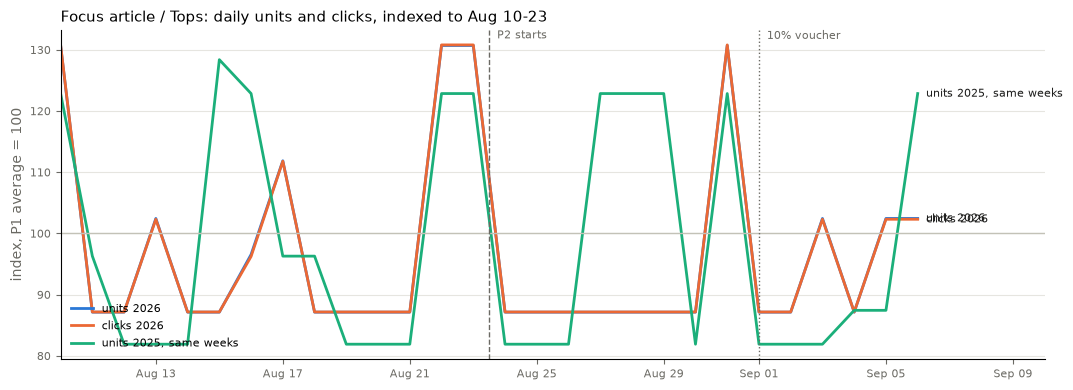

In [52]:
days = q("""
with cur as (
    select d, sum(sales) as units, sum(clicks) as clicks
    from daily join cohort using (product_id)
    where d between date '2026-08-10' and date '2026-09-06' group by 1
),
ly as (
    select d + 364 as d, sum(sales) as units_2025
    from daily join cohort using (product_id)
    where d + 364 between date '2026-08-10' and date '2026-09-06' group by 1
)
select * from cur join ly using (d) order by d
""")
p1_mask = days.d <= pd.Timestamp("2026-08-23")
lines = {"units 2026": ("units", "#2a78d6"), "clicks 2026": ("clicks", "#eb6834"), "units 2025, same weeks": ("units_2025", "#1baf7a")}

fig, ax = plt.subplots(figsize=(11, 4))
for label, (col, color) in lines.items():
    idx = 100 * days[col] / days.loc[p1_mask, col].mean()
    ax.plot(days.d, idx, color=color, lw=2, label=label)
    ax.annotate(label, (days.d.iloc[-1], idx.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                color="#1a1a19", fontsize=8, va="center")
ax.axhline(100, color="#c3c2b7", lw=1)
ax.axvline(pd.Timestamp("2026-08-23 12:00"), color="#6b6a64", ls="--", lw=1)
ax.axvline(pd.Timestamp("2026-09-01"), color="#6b6a64", ls=":", lw=1)
ax.text(pd.Timestamp("2026-08-23 18:00"), ax.get_ylim()[1], "P2 starts", fontsize=8, color="#6b6a64", va="top")
ax.text(pd.Timestamp("2026-09-01 06:00"), ax.get_ylim()[1], "10% voucher", fontsize=8, color="#6b6a64", va="top")
ax.set_ylabel("index, P1 average = 100", color="#6b6a64")
ax.set_title("Focus article / Tops: daily units and clicks, indexed to Aug 10-23", loc="left", fontsize=11)
ax.tick_params(colors="#6b6a64", labelsize=8)
ax.grid(axis="y", color="#e6e5e0", lw=0.8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_xlim(days.d.min(), days.d.max() + pd.Timedelta(days=4))
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

### 4.4 What it means for Sep 7–20, and a sensitivity check

The final model is fitted here because the memo needs its cohort number. It is the same LightGBM, trained on all origins whose targets end by Sep 6 (adds origins Aug 16 and Aug 23). Part 5 reuses it.

In [53]:
VOUCHER_UPLIFT = 1.02

extra = build_features([pd.Timestamp("2026-08-16"), VALID_ORIGIN])
train_final = pd.concat([train, extra], ignore_index=True)
assert train_final.target_date.max() <= FINAL_ORIGIN
final_model = lgb.LGBMRegressor(**LGB_PARAMS).fit(train_final[FEATURES], train_final.target)

fcst["lightgbm"] = final_model.predict(fcst[FEATURES])
fcst["lightgbm_voucher"] = fcst.lightgbm * VOUCHER_UPLIFT
fcst["baseline_14"] = np.where(fcst.mean_14.notna(), fcst.mean_14 * fcst.dow_factor, fcst.baseline)

coh = fcst[fcst.is_cohort]
cohort_view = pd.Series({
    "P1 actual, Aug 10-23": p1.units,
    "P2 actual, Aug 24-Sep 6": p2.units,
    "Sep 7-20 baseline (28-day level)": coh.baseline.sum(),
    "Sep 7-20 baseline (14-day level)": coh.baseline_14.sum(),
    "Sep 7-20 LightGBM": coh.lightgbm.sum(),
    "Sep 7-20 LightGBM + 2% voucher": coh.lightgbm_voucher.sum(),
}, name="cohort units").round(0).astype(int).to_frame()
cohort_view["vs P2"] = (cohort_view["cohort units"] / p2.units - 1).map("{:+.1%}".format)
print(f"train_final: {len(train_final):,} rows, last target {train_final.target_date.max().date()}")
cohort_view

train_final: 2,729,901 rows, last target 2026-09-06


,cohort units,vs P2
"P1 actual, Aug 10-23",1189,+6.9%
"P2 actual, Aug 24-Sep 6",1112,+0.0%
Sep 7-20 baseline (28-day level),1150,+3.4%
Sep 7-20 baseline (14-day level),1112,+0.0%
Sep 7-20 LightGBM,1102,-0.9%
Sep 7-20 LightGBM + 2% voucher,1124,+1.1%


**Sensitivity: how much weight to give the latest weeks.** The planner's question is about whether the latest, lower level should carry more weight. I re-ran the baseline with a 14-day level instead of 28 days on both historical windows. I also re-scored the test window without the repaired targets, to check that my repairs don't drive the result.

In [54]:
sens = {}
for w, (origin, ev) in WINDOWS.items():
    b14 = np.where(ev.mean_14.notna(), ev.mean_14 * ev.dow_factor, ev.baseline)
    for scope, mask in [("all", np.ones(len(ev), bool)), ("cohort", ev.is_cohort.values)]:
        for name, pred in [("baseline 28-day", ev.baseline.values), ("baseline 14-day", b14)]:
            r = metrics(ev.target.values[mask], pred[mask])
            sens[(w, scope, name)] = {"WAPE": r["WAPE"], "bias": r["bias"]}
display(pd.DataFrame(sens).T.rename_axis(["window", "scope", "level"]).round(4).unstack("level"))

s = scored["test"]
rec = s[s.target_source == "recorded"]
pd.DataFrame({
    (scope, m): {k: round(v, 4) for k, v in metrics(part.target, part[m]).items()} | {"rows": len(part)}
    for scope, part in [("all, recorded only", rec), ("cohort, recorded only", rec[rec.is_cohort])]
    for m in ["baseline", "lightgbm"]
}).T

WAPE                            bias                
level         baseline 14-day baseline 28-day baseline 14-day baseline 28-day
window scope                                                                 
select all             0.1236          0.1235          0.0311          0.0113
       cohort          0.1631          0.1609          0.0446          0.0391
test   all             0.2142          0.2243          0.1055          0.1227
       cohort          0.1536          0.1662          0.0692          0.0931

WAPE     MAE    RMSE    bias     rows
all, recorded only    baseline  0.2244  0.8935  1.4235  0.1228  54574.0
                      lightgbm  0.2130  0.8479  1.3293  0.1047  54574.0
cohort, recorded only baseline  0.1652  0.3549  0.4426  0.0914    513.0
                      lightgbm  0.1440  0.3093  0.3940  0.0688    513.0

**Cost of being wrong.** Profit and purchase cost per unit come from the cohort's transaction lines (E5). The liquidation value comes from the stock table. My assumption: an unsold unit is eventually liquidated, so it costs purchase cost − liquidation value, and a missed sale costs the line profit.

In [55]:
profit_u = e5.profit_per_unit.mean()
cost_u = e5.purchase_cost_per_unit.mean()
liq_u = e4.avg_liquidation_value.iloc[-1]
drop = p2.units / p1.units - 1
units_at_stake = abs(drop) * coh.lightgbm_voucher.sum()
pd.Series({
    "profit per unit sold": round(profit_u, 2),
    "loss per unsold unit (cost - liquidation)": round(cost_u - liq_u, 2),
    "units at stake (planner's cut on the forecast)": round(units_at_stake),
    "cost if we cut and demand holds (lost profit)": round(units_at_stake * profit_u),
    "cost if we don't cut and demand drops (overstock)": round(units_at_stake * (cost_u - liq_u)),
}).to_frame("value")

,value
profit per unit sold,9.00
loss per unsold unit (cost - liquidation),1.14
units at stake (planner's cut on the forecast),73.00
cost if we cut and demand holds (lost profit),655.00
cost if we don't cut and demand drops (overstock),83.00


### Investigation results and limitations

**Forecast accuracy (4.1).** On the test window LightGBM beats the baseline overall (WAPE 0.2129 vs 0.2243, bias +0.105 vs +0.123) and on the cohort (0.1449 vs 0.1662, bias +0.070 vs +0.093). Both over-forecast because demand fell inside the window. Dropping the 298 repaired targets changes WAPE by less than 0.001 (0.2130 / 0.2244).

**Observed (facts)**
- The planner is right. 37 cohort products, all online every day in both periods; units 1,189 → 1,112 (−6.5%). The change is −5.8% to −6.5% on every version of the data, so it isn't caused by my cleaning.
- Clicks 135,854 → 127,056 (−6.5%). Units per 1,000 clicks are 8.752 in both periods. Cost per click didn't move (0.0065), so marketing spend fell with clicks (879 → 826).
- Units moved with clicks in every product group and in both years. The same weeks of 2025: cohort −2.7%, other Summer −6.4%, non-Summer −2.7%. In 2026 every group fell more: cohort −6.5%, other Summer −16.9%, non-Summer −7.2%.
- P1 had no promotion; the 10% voucher started Sep 1, inside P2. Revenue per unit went from 13.23 to 12.42 with red-price discounts near 0 in both periods. No cohort product had zero stock in any snapshot since May.

**Interpretation**
- E1 (traffic) explains the whole drop: fewer clicks, same conversion. E3 (promotion), E4 (availability) and E5 (price) are contradicted by the data.
- E2 (season) and E1 overlap: clicks dip every year into September, and most for Summer products, so part of the drop is seasonal. This year the click dip is 2.5–3× last year's in every group (`clicks_change` in E2), which points to a broader cut in paid traffic as well. All clicks are paid and cost per click is flat, so this data can't split "fewer people searching" from "less budget".

**For the Sep 7–20 forecast**
- The model already starts from the lower level. The LightGBM cohort forecast is 1,102 units (1,124 with the +2% voucher), against 1,112 sold in P2 and 1,189 in P1. Cutting it by the planner's 6.5% would count the same drop twice.
- Sensitivity: a 14-day level instead of 28 days improves the baseline on the test window (WAPE 0.2243 → 0.2142) and does nothing on the selection window (0.1235 → 0.1236). So results depend on how fast the forecast follows a level change. That is sensitivity, not proof: the 14-day level only wins in the one window where sales fell. On the cohort for Sep 7–20 it gives 1,112 vs 1,150, about the same as LightGBM.

**Assumptions and limitations**
- Traffic in Sep 7–20 is assumed to stay near the late-August level. The Sep 7–20 traffic rows are after the cutoff. This assumption decides the number: at a constant 8.75 units per 1,000 clicks, every 1% of clicks is 1% of units.
- The +2% voucher comes from six days of conversion. Cohort voucher spend per unit was lower in P2 (0.677) than in P1 (0.850), even with the campaign live, so the evidence for an uplift is weak.
- No dated prices. Stock is 7 snapshots. I read `profit` as contribution per line and `end_liquidation_value` as a per-unit value; neither is documented.
- In the test window the model over-forecast the cohort by 7.0% (bias +0.070) because it couldn't see the traffic drop coming. If traffic falls further in September, the same will happen.

### Client memo (maximum 300 words, 3–5 bullets)

- **Recommendation: don't cut the Focus article / Tops forecast further. Plan about 1,120 units for Sep 7–20, and adjust it to the marketing plan.** [Fact] Our forecast (1,102 units, 1,124 with the voucher) already sits at the late-August level: 1,112 units sold Aug 24–Sep 6, against 1,189 in Aug 10–23. Cutting another 6.5% would count the same drop twice.
- **The drop follows traffic, not demand per visitor.** [Fact] Units fell 6.5% and clicks fell 6.5%; units per 1,000 clicks were 8.75 in both periods. All 37 products were online every day, the earlier period had no promotion, and price per unit fell. [Interpretation] Fewer paid clicks explain the change, not weaker interest in the products.
- **Main uncertainty: end of season or lower spend?** [Fact] The same weeks last year fell 2.7%, and other Summer products fell 16.9% this year. [Interpretation] Part of the drop is seasonal and may continue into September; in late August our model over-forecast this group by 7.0% for that reason. The input that would change my number most is the Sep 7–20 paid-traffic plan for this group: each 1% fewer clicks means about 1% fewer units.
- **Cost of being wrong.** [Assumption] A missed sale loses the line profit (about 9.00 per unit); an unsold unit loses purchase cost minus liquidation value (about 1.14). Cutting 73 units when demand holds costs about 655 in lost profit; not cutting when demand falls costs about 83 in overstock. Under-forecasting is about 8× as expensive, so I lean high. I would change this if planned traffic is below late August (scale down in proportion), or if clearing unsold summer tops costs much more than the stock table's liquidation value suggests.

## Part 5: Generate Submission Predictions

Generate predictions for September 7–20, 2026, using the exact product/date pairs in `sample_prediction.csv`. Save the required `predictions.csv` file.

### 5.1 Forecast for Sep 7–20

`final_model` is the LightGBM from 4.4, trained on every origin whose targets end by Sep 6. `fcst` holds the features at the Sep 6 origin for the exact 54,880 sample pairs (key check in 2.4). The submitted number is the model forecast × 1.02 for the 10% voucher that runs through the whole window (Part 2.5). Both versions are shown.

In [56]:
last14 = q(f"select sum(sales) as units from daily where d > date '{FINAL_ORIGIN.date()}' - 14 and d <= date '{FINAL_ORIGIN.date()}'").units[0]
pd.DataFrame({
    scope: {"last 14 days actual (Aug 24 - Sep 6)": last14 if scope == "all" else p2.units,
            "Sep 7-20 LightGBM": df.lightgbm.sum(),
            "Sep 7-20 LightGBM + 2% voucher (submitted)": df.lightgbm_voucher.sum()}
    for scope, df in [("all", fcst), ("cohort", fcst[fcst.is_cohort])]
}).round(0).astype(int)

,all,cohort
last 14 days actual (Aug 24 - Sep 6),218560,1112
Sep 7-20 LightGBM,217272,1102
Sep 7-20 LightGBM + 2% voucher (submitted),221618,1124


In [57]:
sample = pd.read_csv("sample_prediction.csv", dtype={"product_id": str})
out = fcst.assign(date=pd.to_datetime(fcst.target_date).dt.strftime("%Y-%m-%d"),
                  predicted_sales=fcst.lightgbm_voucher.clip(lower=0).round(4))[["product_id", "date", "predicted_sales"]]
pred = sample[["product_id", "date"]].merge(out, on=["product_id", "date"], how="left", validate="one_to_one")

assert len(pred) == len(sample) == 54880
assert pred.predicted_sales.notna().all() and (pred.predicted_sales >= 0).all()
assert not pred.duplicated(["product_id", "date"]).any()
assert pred.date.min() == "2026-09-07" and pred.date.max() == "2026-09-20"
assert pred.product_id.map(type).eq(str).all()

pred.to_csv("predictions.csv", index=False)
check = pd.read_csv("predictions.csv", dtype={"product_id": str})
print(f"predictions.csv: {len(check):,} rows, {check.product_id.nunique():,} products, "
      f"{check.date.min()} -> {check.date.max()}, min {check.predicted_sales.min():.3f}, "
      f"max {check.predicted_sales.max():.3f}, total {check.predicted_sales.sum():,.0f}")
check.head()

predictions.csv: 54,880 rows, 3,920 products, 2026-09-07 -> 2026-09-20, min 1.377, max 9.592, total 221,618


,product_id,date,predicted_sales
0,2_x_669800,2026-09-07,3.5577
1,2_x_669800,2026-09-08,3.4927
2,2_x_669800,2026-09-09,3.2238
3,2_x_669800,2026-09-10,3.4845
4,2_x_669800,2026-09-11,3.6306


### Export and checks

- **How to reproduce:** run the notebook top to bottom. With the cached predictions in `model_runs/` this takes ~5 min. `predictions.csv` is written to the project root by the last code cell. To refit everything, delete `model_runs/`. NHITS then needs `requirements-extra.txt` and the run takes ~40 min.
- **Model:** LightGBM (Tweedie loss), trained on 55 weekly origins with targets up to Sep 6. Features come only from data up to the Sep 6 origin, and the final forecast uses the promotion plan known on Sep 6.
- **Voucher:** submitted forecast = model × 1.02 (Part 2.5). The 4.5 limitations explain why that evidence is weak; the table above shows the totals without it.
- **Checks in the cell above:**
  - row count and keys match `sample_prediction.csv` one-to-one (54,880 rows, merged with `validate="one_to_one"`);
  - no missing or negative values, no duplicate keys;
  - dates are Sep 7–20 in YYYY-MM-DD format, and `product_id` is a string;
  - the file is read back after saving.
- **Unfinished:** clicks as a feature with an explicit traffic scenario; checking the model choice on more than one selection window; Prophet on the full catalog.

## Evaluation Criteria

Submissions are assessed on data reasoning (30%), forecasting and validation (25%), business judgment (25%), and communication (20%). Runnable code and the required prediction file are basic deliverables. Model complexity and extensive tuning do not earn additional credit by themselves.
